In [100]:
import sys
RE_path = './'
sys.path.insert(1, RE_path)


In [101]:
import numpy as np
from matplotlib import pyplot as plt
import RE
import importlib
importlib.reload(RE)
from RE import *
import RESolver as solver
importlib.reload(solver)
import scipy.constants as const

# Example Solution using SPARC-like Parameters #

In [55]:
def getj0(I0,nx):
    r = np.linspace(0,1,nx)
    jp0 = 13.3e6 * (1-r**2)**0.5 # A/m**2
    javg = 2 * np.pi * np.trapz(jp0*r,x=r) / (np.pi * 1**2) # average jinit
    rmax = np.sqrt(I0 / (javg * np.pi)) # radius required to preserve total current
    return jp0, rmax, r

# Constants
R0 = 1.85 # [m]
a = 0.57 # [m]
Zeff = 3
T = 10 # eV
ne = 3e20 # per m**3
lnA = 15
eta = 0.51 * getTransSpitzerResistivity(lnA,T,Zeff) * 0.01 # Ohm-m
    
# Initial Conditions
jp0, rmax, r = getj0(8.7e6,128)
jr0 = 1e5 * 0.5*(2+np.sin(2*np.pi*r/rmax/1))

constants = [rmax, R0, ne, T, Zeff, lnA, eta]
init_conditions = [jp0, jr0]

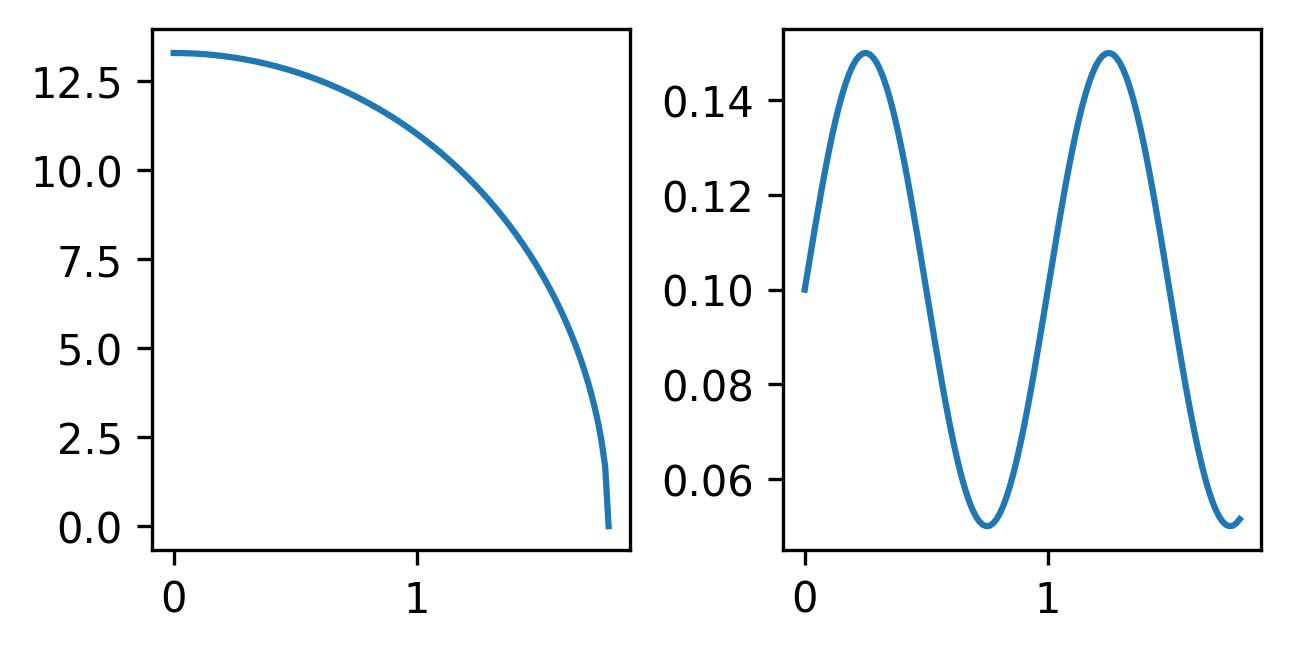

In [56]:
fig, axs = plt.subplots(1,2,dpi=300,figsize=(4,2))

axs[0].plot(r/rmax,jp0/1e6)
axs[1].plot(r/rmax,jr0/1e6)

fig.tight_layout(pad=0.1)

Configure the solver

In [57]:
import RESolver as solver
importlib.reload(solver)

out1 = solver.solve(constants=constants,
                        init_conditions=init_conditions,
                        tmax=0.1e-3,
                        CFL=0.4,
                        RE_sources=[0,0,0,1], # [iDreicer, iTritBeta, iCompton, iAvalanche]
                        cre=3e8,
                        nprint=100,
                        verbose=True)

out2 = solver.solve(constants=constants,
                        init_conditions=init_conditions,
                        tmax=0.2e-3,
                        CFL=0.4,
                        RE_sources=[0,0,0,1], # [iDreicer, iTritBeta, iCompton, iAvalanche]
                        cre=3e8,
                        nprint=100,
                        verbose=True)


out3 = solver.solve(constants=constants,
                        init_conditions=init_conditions,
                        tmax=0.4e-3,
                        CFL=0.4,
                        RE_sources=[0,0,0,1], # [iDreicer, iTritBeta, iCompton, iAvalanche]
                        cre=3e8,
                        nprint=500,
                        verbose=True)

out4 = solver.solve(constants=constants,
                        init_conditions=init_conditions,
                        tmax=0.8e-3,
                        CFL=0.8,
                        RE_sources=[0,0,0,1], # [iDreicer, iTritBeta, iCompton, iAvalanche]
                        cre=3e8,
                        nprint=500,
                        verbose=True)




nx = 128

I0 [MA] = 8.71

Ir (t = 0) [MA] = 0.0953

iDreicer = 0,iTritBeta = 0, iCompton = 0, iAvalanche = 1

Runaway Velocity [m/s]= 3e+08

Time Step dt [ms] = 0.00013

Seed Ir(t=dt) [MA] = 0.0953

step = 100, time [ms] = 0.01, Ip [MA] = 8.34, E/Ec [-] = 4259.72
step = 200, time [ms] = 0.03, Ip [MA] = 8.10, E/Ec [-] = 4227.61
step = 300, time [ms] = 0.04, Ip [MA] = 7.89, E/Ec [-] = 4195.25
step = 400, time [ms] = 0.05, Ip [MA] = 7.71, E/Ec [-] = 4161.30
step = 500, time [ms] = 0.07, Ip [MA] = 7.54, E/Ec [-] = 4125.06
step = 600, time [ms] = 0.08, Ip [MA] = 7.38, E/Ec [-] = 4086.03
step = 700, time [ms] = 0.09, Ip [MA] = 7.24, E/Ec [-] = 4043.76
nx = 128

I0 [MA] = 8.71

Ir (t = 0) [MA] = 0.0953

iDreicer = 0,iTritBeta = 0, iCompton = 0, iAvalanche = 1

Runaway Velocity [m/s]= 3e+08

Time Step dt [ms] = 0.00013

Seed Ir(t=dt) [MA] = 0.0953

step = 100, time [ms] = 0.01, Ip [MA] = 8.34, E/Ec [-] = 4259.72
step = 200, time [ms] = 0.03, Ip [MA] = 8.10, E/Ec [-] = 4227.61
step = 300, time 

Show results

(0.0, 9.139121157152772)

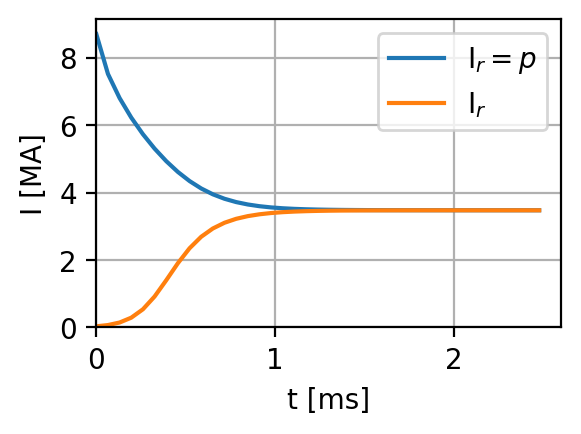

In [58]:
# Show Results
t, Ip, Ir = np.array(out['t']), np.array(out['Ip']), np.array(out['Ir'])
fig, axs = plt.subplots(1, 1, figsize=(3,2), dpi=200, sharex=True)

axs.plot(t * 1e3, Ip / 1e6, label='I$_r=p$')
axs.plot(t * 1e3, Ir / 1e6, label='I$_r$')
axs.set_xlabel('t [ms]')
axs.set_ylabel('I [MA]')
axs.grid()
axs.legend()
axs.set_xlim(xmin=0)
axs.set_ylim(ymin=0)



Final Profile

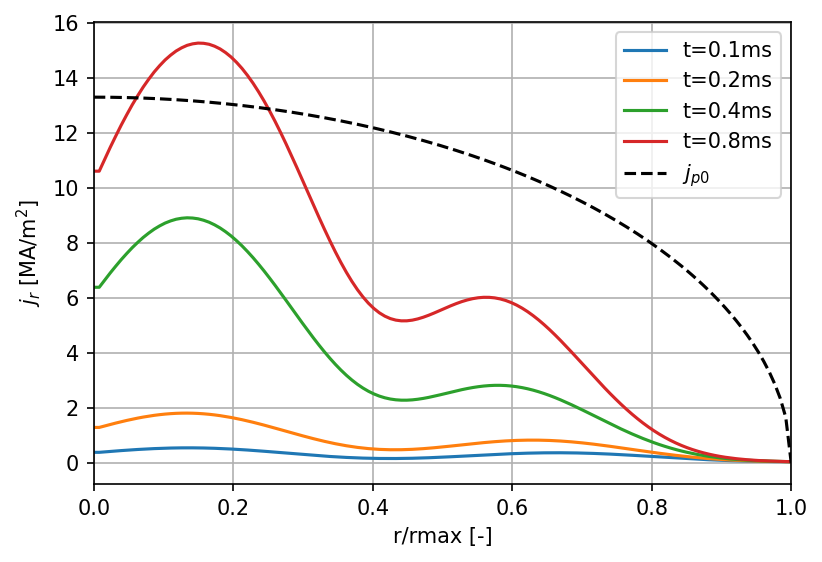

In [59]:
# Create the radial array (assuming all outputs share the same shape and rmax)
r = np.linspace(0, rmax, out1['jr'].shape[0])

plt.figure(figsize=(6, 4), dpi=150)

# Plot jr for out1 through out4
plt.plot(r / rmax, out1['jr'] / 1e6, label='t=0.1ms')
plt.plot(r / rmax, out2['jr'] / 1e6, label='t=0.2ms')
plt.plot(r / rmax, out3['jr'] / 1e6, label='t=0.4ms')
plt.plot(r / rmax, out4['jr'] / 1e6, label='t=0.8ms')

# Plot the initial current profile (jp0) for reference
plt.plot(r / rmax, jp0 / 1e6, label='$j_{p0}$', linestyle='--', color='black')

plt.xlabel('r/rmax [-]') 
plt.ylabel('$j_r$ [MA/m$^2$]')
plt.xlim([0, 1])
plt.grid(True)
plt.legend()
plt.show()

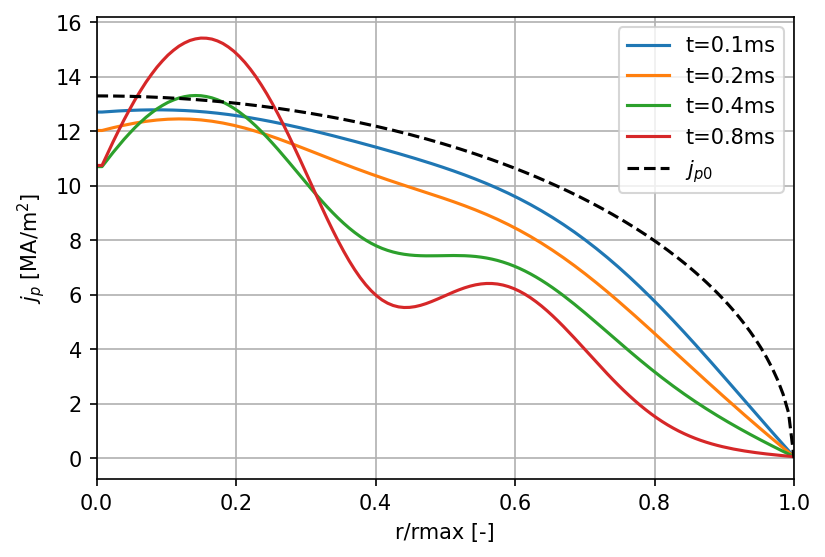

In [60]:
# Create the radial array (assuming all outputs share the same shape and rmax)
r = np.linspace(0, rmax, out1['jr'].shape[0])

plt.figure(figsize=(6, 4), dpi=150)

# Plot jr for out1 through out4
plt.plot(r / rmax, out1['jp'] / 1e6, label='t=0.1ms')
plt.plot(r / rmax, out2['jp'] / 1e6, label='t=0.2ms')
plt.plot(r / rmax, out3['jp'] / 1e6, label='t=0.4ms')
plt.plot(r / rmax, out4['jp'] / 1e6, label='t=0.8ms')

# Plot the initial current profile (jp0) for reference
plt.plot(r / rmax, jp0 / 1e6, label='$j_{p0}$', linestyle='--', color='black')

plt.xlabel('r/rmax [-]') 
plt.ylabel('$j_p$ [MA/m$^2$]')
plt.xlim([0, 1])
plt.grid(True)
plt.legend()
plt.show()

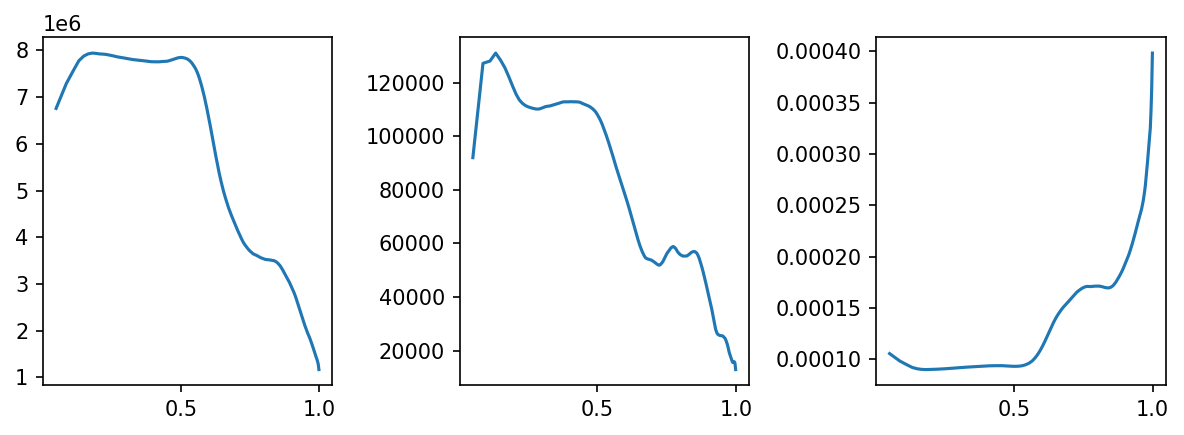

In [102]:
data = np.load('./data/saved_data_tid_200.npz')
psi = data['psi']
jy = data['jy']
jre = data['jre']
eta = data['eta']
r = np.sqrt(psi)


# Create subplots for each variable
fig, axs = plt.subplots(1, 3, figsize=(8, 3), dpi=150)

# Plot psi
axs[0].plot(r,jy)

# Plot jy
axs[1].plot(r,jre)

# Plot jre
axs[2].plot(r,eta)

plt.tight_layout()
plt.show()


In [103]:
# Constants
R0 = 1.85 # [m]
a = np.max(r) # [m]
Zeff = 3
T = 10 # eV
ne = 3e20 # per m**3
lnA = 15
# eta = 0.51 * getTransSpitzerResistivity(lnA,T,Zeff) * 0.01 # Ohm-m
eta = eta
    
# Initial Conditions
jp0 = jy
jr0 = jre

constants = [a, R0, ne, T, Zeff, lnA, eta]
init_conditions = [jp0, jr0]

In [104]:
a

0.998749217771909

In [105]:
import RESolver as solver
importlib.reload(solver)

out1 = solver.solve(constants=constants,
                        init_conditions=init_conditions,
                        tmax=0.2e-3,
                        CFL=0.4,
                        RE_sources=[0,0,0,1], # [iDreicer, iTritBeta, iCompton, iAvalanche]
                        cre=3e8,
                        nprint=100,
                        verbose=True)


out2 = solver.solve(constants=constants,
                        init_conditions=init_conditions,
                        tmax=0.4e-3,
                        CFL=0.4,
                        RE_sources=[0,0,0,1], # [iDreicer, iTritBeta, iCompton, iAvalanche]
                        cre=3e8,
                        nprint=100,
                        verbose=True)


out3 = solver.solve(constants=constants,
                        init_conditions=init_conditions,
                        tmax=0.8e-3,
                        CFL=0.4,
                        RE_sources=[0,0,0,1], # [iDreicer, iTritBeta, iCompton, iAvalanche]
                        cre=3e8,
                        nprint=500,
                        verbose=True)



nx = 200

I0 [MA] = 11.7

Ir (t = 0) [MA] = 0.16

iDreicer = 0,iTritBeta = 0, iCompton = 0, iAvalanche = 1

Runaway Velocity [m/s]= 3e+08

Time Step dt [ms] = 3.18e-05

Seed Ir(t=dt) [MA] = 0.16

step = 100, time [ms] = 0.00, Ip [MA] = 11.41, E/Ec [-] = 3434.93
step = 200, time [ms] = 0.01, Ip [MA] = 11.29, E/Ec [-] = 3488.97
step = 300, time [ms] = 0.01, Ip [MA] = 11.19, E/Ec [-] = 3522.84
step = 400, time [ms] = 0.01, Ip [MA] = 11.11, E/Ec [-] = 3547.70
step = 500, time [ms] = 0.02, Ip [MA] = 11.03, E/Ec [-] = 3567.33
step = 600, time [ms] = 0.02, Ip [MA] = 10.96, E/Ec [-] = 3583.51
step = 700, time [ms] = 0.02, Ip [MA] = 10.90, E/Ec [-] = 3597.21
step = 800, time [ms] = 0.03, Ip [MA] = 10.84, E/Ec [-] = 3609.02
step = 900, time [ms] = 0.03, Ip [MA] = 10.78, E/Ec [-] = 3619.33
step = 1000, time [ms] = 0.03, Ip [MA] = 10.73, E/Ec [-] = 3628.43
step = 1100, time [ms] = 0.03, Ip [MA] = 10.68, E/Ec [-] = 3636.50
step = 1200, time [ms] = 0.04, Ip [MA] = 10.63, E/Ec [-] = 3643.70
step = 13

step = 5700, time [ms] = 0.18, Ip [MA] = 9.19, E/Ec [-] = 3559.07
step = 5800, time [ms] = 0.18, Ip [MA] = 9.17, E/Ec [-] = 3549.63
step = 5900, time [ms] = 0.19, Ip [MA] = 9.15, E/Ec [-] = 3539.81
step = 6000, time [ms] = 0.19, Ip [MA] = 9.12, E/Ec [-] = 3529.61
step = 6100, time [ms] = 0.19, Ip [MA] = 9.10, E/Ec [-] = 3519.04
step = 6200, time [ms] = 0.20, Ip [MA] = 9.08, E/Ec [-] = 3508.08
step = 6300, time [ms] = 0.20, Ip [MA] = 9.06, E/Ec [-] = 3496.73
step = 6400, time [ms] = 0.20, Ip [MA] = 9.04, E/Ec [-] = 3484.98
step = 6500, time [ms] = 0.21, Ip [MA] = 9.01, E/Ec [-] = 3472.84
step = 6600, time [ms] = 0.21, Ip [MA] = 8.99, E/Ec [-] = 3460.29
step = 6700, time [ms] = 0.21, Ip [MA] = 8.97, E/Ec [-] = 3447.34
step = 6800, time [ms] = 0.22, Ip [MA] = 8.95, E/Ec [-] = 3433.97
step = 6900, time [ms] = 0.22, Ip [MA] = 8.93, E/Ec [-] = 3420.18
step = 7000, time [ms] = 0.22, Ip [MA] = 8.91, E/Ec [-] = 3405.97
step = 7100, time [ms] = 0.23, Ip [MA] = 8.89, E/Ec [-] = 3391.33
step = 720

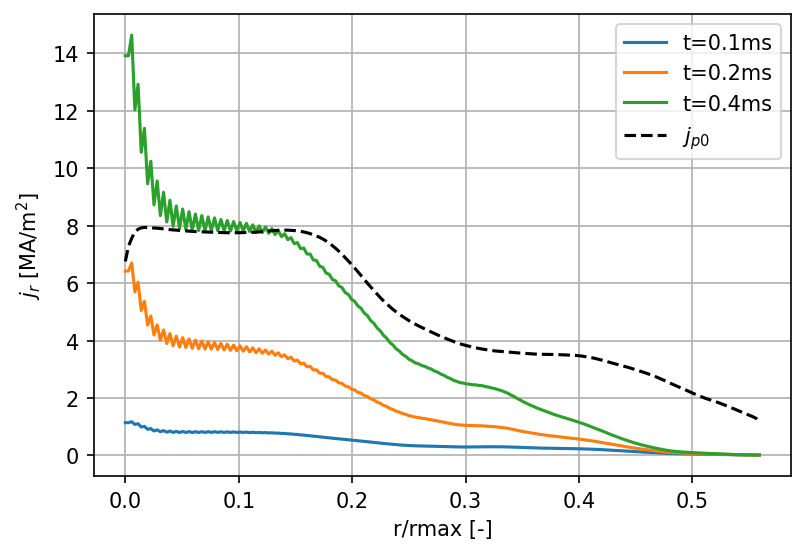

In [107]:
# Create the radial array (assuming all outputs share the same shape and rmax)
r = np.linspace(0, rmax, out1['jr'].shape[0])

plt.figure(figsize=(6, 4), dpi=150)

# Plot jr for out1 through out4
plt.plot(r , out1['jr'] / 1e6, label='t=0.1ms')
plt.plot(r , out2['jr'] / 1e6, label='t=0.2ms')
plt.plot(r , out3['jr'] / 1e6, label='t=0.4ms')

# Plot the initial current profile (jp0) for reference
plt.plot(r , jp0 / 1e6, label='$j_{p0}$', linestyle='--', color='black')

plt.xlabel('r/rmax [-]') 
plt.ylabel('$j_r$ [MA/m$^2$]')
plt.grid(True)
plt.legend()
plt.show()